# Stage 6 — The field model inside the flap-control loop

**Vamsi Gudipati**

This notebook puts the Stage 5 chain (parameters → latent coordinates of the flow field → lift and drag) in place of the Stage 3 coefficient surrogate inside the Stage 4 flap-control environment, using the saved Stage 5 models without retraining them. I compare the two aerodynamic laws and thin-airfoil theory at the operating point, check a NumPy forward pass of the chain against Keras and time it, train PPO agents with three seeds in both environments and cross-test them on the same gusts, decode the steady pressure field along one controlled flight, and probe how far the two laws disagree outside their shared training range. The Stage 4 code this notebook needs is copied in verbatim, and the first line of each block names where it comes from.

Portfolio page: https://vamsigudipati.github.io/airfoil-rom-betavae-design.html


# The Stage 5 field model in place of the Stage 3 coefficient surrogate, inside the Stage 4 environment

An experiment that spans Stages 3 to 5. Stage 4 trains a flap controller in an environment whose steady aerodynamics, $(C_L, C_D)$ at the equivalent angle of attack, come from a coefficient surrogate (Stage 3). Stage 5 builds a different route from the same 489-case database to the same two numbers: parameters → latent coordinates of the whole flow field → aerodynamic head. This notebook measures what changes when one replaces the other.

- **A.** Both aerodynamic functions, and thin-airfoil theory, at the operating point of Stage 4.
- **B.** The Stage 4 environment with only the aerodynamic function exchanged, as a NumPy forward pass checked against Keras.
- **C.** PPO agents (seeds 0, 1, 2) trained in both environments and cross-tested in both on the same five gusts.
- **D.** Steady pressure fields decoded along one controlled flight.
- **E.** The training range that both models share, and how far they disagree outside it.

The Stage 4 code below is copied verbatim; the first line of each block says what it is. The surrogate files and the coefficient table are those of Stage 3, and the Stage 5 models are those Stage 5 saved.

In [1]:
# ---- copied verbatim from Stage 4 ----
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import PPO, SAC, TD3
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.noise import NormalActionNoise

SEED = 0

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [2]:
# ================================================================
# SETUP (this notebook)
# ================================================================
import time, json
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

RES = Path("../results/06_field_model_in_control_loop"); RES.mkdir(exist_ok=True)
MODELS = Path("../models/06_field_model_in_control_loop"); MODELS.mkdir(exist_ok=True)
L12 = Path("../models/05_airfrans_rom_betavae_design")
R104 = Path("../../airfoil-cfd-surrogate-drl/models/04_airfoil_gust_control_cfd_surrogate")
TOTAL_TIMESTEPS = 50_000          # as in Stage 4
PPO_SEEDS = [0, 1, 2]
print("Stage 5 models:", sorted(p.name for p in L12.glob("*seed2026*")))

Stage 5 models: ['aerodynamic_head_pod_seed2026.keras', 'aerodynamic_head_pod_seed2026_latent_scaler.joblib', 'aerodynamic_head_vae_seed2026.keras', 'aerodynamic_head_vae_seed2026_latent_scaler.joblib', 'latent_surrogate_pod_seed2026.json', 'latent_surrogate_pod_seed2026.keras', 'latent_surrogate_vae_seed2026.json', 'latent_surrogate_vae_seed2026.keras']


In [3]:
# ---- copied verbatim from Stage 4 ----
MODEL_FILE = Path("../data/airfrans_cl_cd_surrogate.keras")
SCALER_FILE = Path("../data/airfrans_cl_cd_scalers.joblib")

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"{MODEL_FILE.name} was not found in {Path.cwd()}. "
        "Run Stage 3 first or change MODEL_FILE."
    )

if not SCALER_FILE.exists():
    raise FileNotFoundError(
        f"{SCALER_FILE.name} was not found in {Path.cwd()}. "
        "Run Stage 3 first or change SCALER_FILE."
    )

surrogate_model = tf.keras.models.load_model(MODEL_FILE)

surrogate_data = joblib.load(SCALER_FILE)
x_scaler = surrogate_data["x_scaler"]
y_scaler = surrogate_data["y_scaler"]

print("Loaded model:  ", MODEL_FILE)
print("Loaded scalers:", SCALER_FILE)

Loaded model:   ../data/airfrans_cl_cd_surrogate.keras
Loaded scalers: ../data/airfrans_cl_cd_scalers.joblib


In [4]:
# ---- copied verbatim from Stage 4 ----
def predict_airfrans_aero(
    reynolds,
    alpha_deg,
    m=2.0,
    p=4.0,
    t=12.0,
):
    x = np.array([[
        reynolds / 1.0e6,
        alpha_deg,
        m,
        p,
        t,
    ]], dtype=float)

    x_scaled = x_scaler.transform(x)
    y_scaled = surrogate_model.predict(x_scaled, verbose=0)
    cl, cd = y_scaler.inverse_transform(y_scaled)[0]

    return float(cl), float(cd)


cl_demo, cd_demo = predict_airfrans_aero(
    reynolds=4.0e6,
    alpha_deg=5.0,
    m=2.0,
    p=4.0,
    t=12.0,
)

print(f"Example prediction: CL={cl_demo:.4f}, CD={cd_demo:.5f}")

Example prediction: CL=0.7595, CD=0.00967


In [5]:
# ---- copied verbatim from Stage 4 ----
# ================================================================
# FAST SURROGATE CALL — identical network evaluated with NumPy
# ================================================================
import time

keras_predict_airfrans_aero = predict_airfrans_aero
_layers = [(layer.get_weights()[0], layer.get_weights()[1], layer.activation.__name__)
           for layer in surrogate_model.layers]
_xm, _xs = x_scaler.mean_, x_scaler.scale_
_ym, _ys = y_scaler.mean_, y_scaler.scale_


def fast_predict_airfrans_aero(reynolds, alpha_deg, m=2.0, p=4.0, t=12.0):
    h = (np.array([reynolds / 1.0e6, alpha_deg, m, p, t]) - _xm) / _xs
    for w, b, act in _layers:
        h = h @ w + b
        if act == "tanh":
            h = np.tanh(h)
        elif act != "linear":
            raise ValueError(act)
    cl, cd = h * _ys + _ym
    return float(cl), float(cd)


rng = np.random.default_rng(0)
checks = np.column_stack([rng.uniform(2e6, 6e6, 200), rng.uniform(-5, 15, 200), rng.uniform(0, 7, 200),
                          rng.uniform(0, 7, 200), rng.uniform(5, 20, 200)])
diff = max(abs(np.subtract(keras_predict_airfrans_aero(*c), fast_predict_airfrans_aero(*c))).max() for c in checks[:50])
t0 = time.time(); [keras_predict_airfrans_aero(*c) for c in checks[:50]]; t_keras = (time.time() - t0) / 50
t0 = time.time(); [fast_predict_airfrans_aero(*c) for c in checks]; t_fast = (time.time() - t0) / 200
print(f"max |Keras - NumPy| over 50 random inputs: {diff:.2e}")
print(f"time per call: Keras predict {1e3 * t_keras:.2f} ms, NumPy {1e3 * t_fast:.3f} ms")
predict_airfrans_aero = fast_predict_airfrans_aero

max |Keras - NumPy| over 50 random inputs: 2.82e-07
time per call: Keras predict 18.29 ms, NumPy 0.012 ms


In [6]:
# ---- copied verbatim from Stage 4 ----
def one_minus_cosine_gust(t, t0, duration, amplitude):
    if t < t0 or t > t0 + duration:
        return 0.0

    xi = (t - t0) / duration
    return 0.5 * amplitude * (1.0 - np.cos(2.0 * np.pi * xi))

In [7]:
# ---- copied verbatim from Stage 4 ----
class AirfoilSurrogateGymEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self,
        dt=0.05,
        horizon=120,
        U_inf=30.0,
        alpha0_deg=5.0,
        cl_target=None,
        max_flap_deg=20.0,
        flap_effectiveness=0.55,
        tau_lift=0.18,
        tau_flap=0.10,
        reynolds=4.0e6,
        naca_m=2.0,
        naca_p=4.0,
        naca_t=12.0,
        random_gust=True,
        gust_amplitude_range=(-3.0, 3.0),
        gust_duration_range=(0.8, 1.8),
        gust_start_range=(1.0, 3.0),
        effort_weight=0.015,
        smoothness_weight=0.020,
        drag_weight=0.020,
    ):
        super().__init__()

        self.dt = dt
        self.horizon = horizon
        self.U_inf = U_inf
        self.alpha0_deg = alpha0_deg
        self.max_flap_deg = max_flap_deg
        self.flap_effectiveness = flap_effectiveness
        self.tau_lift = tau_lift
        self.tau_flap = tau_flap

        self.reynolds = reynolds
        self.naca_m = naca_m
        self.naca_p = naca_p
        self.naca_t = naca_t

        self.random_gust = random_gust
        self.gust_amplitude_range = gust_amplitude_range
        self.gust_duration_range = gust_duration_range
        self.gust_start_range = gust_start_range

        self.effort_weight = effort_weight
        self.smoothness_weight = smoothness_weight
        self.drag_weight = drag_weight

        # If no target is prescribed, use the zero-gust equilibrium lift.
        cl_equilibrium, _ = predict_airfrans_aero(
            self.reynolds,
            self.alpha0_deg,
            self.naca_m,
            self.naca_p,
            self.naca_t,
        )
        self.cl_target = float(cl_equilibrium if cl_target is None else cl_target)

        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(1,),
            dtype=np.float32,
        )

        self.observation_space = spaces.Box(
            low=np.array([-2.0, -2.0, -2.0, -1.5], dtype=np.float32),
            high=np.array([ 2.0,  2.0,  2.0,  1.5], dtype=np.float32),
            dtype=np.float32,
        )

        self.reset()

    def _gust_velocity(self, t):
        return one_minus_cosine_gust(
            t,
            self.gust_start,
            self.gust_duration,
            self.gust_amplitude,
        )

    def _gust_angle_deg(self, t):
        w_g = self._gust_velocity(t)
        return np.rad2deg(np.arctan2(w_g, self.U_inf))

    def _equivalent_alpha_deg(self, gust_angle_deg):
        return (
            self.alpha0_deg
            + gust_angle_deg
            + self.flap_effectiveness * self.flap_deg
        )

    def _aero(self, gust_angle_deg):
        alpha_eq_deg = self._equivalent_alpha_deg(gust_angle_deg)

        cl_qs, cd = predict_airfrans_aero(
            self.reynolds,
            alpha_eq_deg,
            self.naca_m,
            self.naca_p,
            self.naca_t,
        )

        return cl_qs, cd, alpha_eq_deg

    def _get_obs(self):
        gust_angle_deg = self._gust_angle_deg(self.t)

        obs = np.array([
            self.cl / 1.5,
            self.cl_target / 1.5,
            gust_angle_deg / 10.0,
            self.flap_deg / self.max_flap_deg,
        ], dtype=np.float32)

        return np.clip(
            obs,
            self.observation_space.low,
            self.observation_space.high,
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.step_count = 0
        self.t = 0.0
        self.prev_action = 0.0
        self.flap_deg = 0.0

        if self.random_gust:
            self.gust_amplitude = self.np_random.uniform(
                *self.gust_amplitude_range
            )
            self.gust_duration = self.np_random.uniform(
                *self.gust_duration_range
            )
            self.gust_start = self.np_random.uniform(
                *self.gust_start_range
            )
        else:
            self.gust_amplitude = 2.5
            self.gust_duration = 1.3
            self.gust_start = 2.0

        self.cl, self.cd = predict_airfrans_aero(
            self.reynolds,
            self.alpha0_deg,
            self.naca_m,
            self.naca_p,
            self.naca_t,
        )

        return self._get_obs(), {}

    def step(self, action):
        action = np.asarray(action, dtype=np.float32).reshape(-1)
        action_value = float(np.clip(action[0], -1.0, 1.0))

        flap_command_deg = action_value * self.max_flap_deg

        # First-order actuator dynamics.
        self.flap_deg += (
            self.dt / self.tau_flap
        ) * (flap_command_deg - self.flap_deg)

        gust_angle_deg = self._gust_angle_deg(self.t)

        cl_qs, cd, alpha_eq_deg = self._aero(gust_angle_deg)

        # First-order lift dynamics.
        self.cl += (
            self.dt / self.tau_lift
        ) * (cl_qs - self.cl)

        self.cd = cd

        tracking_error = self.cl - self.cl_target
        delta_action = action_value - self.prev_action

        reward = (
            -tracking_error**2
            -self.effort_weight * action_value**2
            -self.smoothness_weight * delta_action**2
            -self.drag_weight * cd
        )

        self.prev_action = action_value
        self.step_count += 1
        self.t = self.step_count * self.dt

        terminated = False
        truncated = self.step_count >= self.horizon

        info = {
            "time": self.t,
            "cl": self.cl,
            "cl_qs": cl_qs,
            "cl_target": self.cl_target,
            "cd": cd,
            "flap_deg": self.flap_deg,
            "flap_command_deg": flap_command_deg,
            "gust_velocity": self._gust_velocity(self.t),
            "gust_angle_deg": self._gust_angle_deg(self.t),
            "alpha_eq_deg": alpha_eq_deg,
            "tracking_error": tracking_error,
        }

        return (
            self._get_obs(),
            float(reward),
            terminated,
            truncated,
            info,
        )

In [8]:
# ---- copied verbatim from Stage 4 ----
def run_episode(env, policy, seed=0):
    obs, _ = env.reset(seed=seed)

    data = {
        "time": [],
        "cl": [],
        "cl_qs": [],
        "cl_target": [],
        "cd": [],
        "flap_deg": [],
        "flap_command_deg": [],
        "gust_velocity": [],
        "gust_angle_deg": [],
        "alpha_eq_deg": [],
        "reward": [],
    }

    terminated = truncated = False

    while not (terminated or truncated):
        action, _ = policy.predict(obs, deterministic=True)

        obs, reward, terminated, truncated, info = env.step(action)

        for key in data:
            if key == "reward":
                data[key].append(reward)
            else:
                data[key].append(info[key])

    return {
        key: np.asarray(value)
        for key, value in data.items()
    }


class ZeroPolicy:
    def predict(self, obs, deterministic=True):
        return np.array([0.0], dtype=np.float32), None

In [9]:
# ---- copied verbatim from Stage 4 (definition only) ----
def episode_metrics(data):
    error = data["cl"] - data["cl_target"]

    return {
        "CL_RMSE": np.sqrt(np.mean(error**2)),
        "mean_abs_flap_deg": np.mean(np.abs(data["flap_deg"])),
        "max_abs_flap_deg": np.max(np.abs(data["flap_deg"])),
        "mean_CD": np.mean(data["cd"]),
        "episode_return": np.sum(data["reward"]),
    }

In [10]:
# ---- copied verbatim from Stage 4 (the four unseen gusts only) ----
test_cases = [
    (-3.5, 1.0),
    (-2.0, 1.7),
    ( 2.0, 1.1),
    ( 3.5, 1.6),
]

In [11]:
# ---- copied verbatim from Stage 4 (trusted range, fly, suite_metrics only) ----
SUITE = [(2.5, 1.3)] + list(test_cases)

cfd_train = pd.read_csv("../data/airfrans_4digit_coefficients.csv").query("split == 'train'")
TRUST_LO, TRUST_HI = float(cfd_train.alpha_deg.min()), float(cfd_train.alpha_deg.max())
print(f"Trusted angle range from the CFD training data: {TRUST_LO:.2f} to {TRUST_HI:.2f} deg")


def fly(policy, amplitude, duration, start=2.0, env_cls=AirfoilSurrogateGymEnv, **env_kw):
    env = env_cls(random_gust=False, **env_kw)
    obs, _ = env.reset(seed=0)
    env.gust_amplitude, env.gust_duration, env.gust_start = amplitude, duration, start
    obs = env._get_obs()
    keys = ["time", "cl", "cl_target", "cd", "flap_deg", "gust_angle_deg", "alpha_eq_deg"]
    out = {k: [] for k in keys + ["reward", "action"]}
    done = False
    while not done:
        action, _ = policy.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        for k in keys:
            out[k].append(info[k])
        out["reward"].append(reward); out["action"].append(float(np.clip(np.ravel(action)[0], -1, 1)))
    return {k: np.asarray(v) for k, v in out.items()}


def suite_metrics(policy, label, gusts=SUITE, **fly_kw):
    row = {"configuration": label}
    rm, fl, mfl, cds, rough, amin, amax, outside = [], [], [], [], [], [], [], []
    for W0, Tg in gusts:
        tr = fly(policy, W0, Tg, **fly_kw)
        m = episode_metrics(tr)
        rm.append(m["CL_RMSE"]); fl.append(m["max_abs_flap_deg"]); mfl.append(m["mean_abs_flap_deg"]); cds.append(m["mean_CD"])
        rough.append(np.mean(np.abs(np.diff(tr["action"]))))
        amin.append(tr["alpha_eq_deg"].min()); amax.append(tr["alpha_eq_deg"].max())
        outside.append(np.mean((tr["alpha_eq_deg"] < TRUST_LO) | (tr["alpha_eq_deg"] > TRUST_HI)))
        row[f"RMSE W0={W0:+.1f},Tg={Tg:.1f}"] = m["CL_RMSE"]
    row.update({"mean_RMSE": np.mean(rm), "max_abs_flap_deg": np.max(fl), "mean_abs_flap_deg": np.mean(mfl),
                "mean_CD": np.mean(cds), "action_roughness": np.mean(rough), "alpha_eq_min": np.min(amin),
                "alpha_eq_max": np.max(amax), "fraction_outside_trusted": np.mean(outside)})
    return row

Trusted angle range from the CFD training data: -4.91 to 14.84 deg


## A. Three aerodynamic laws at the operating point of Stage 4

NACA 2412-like section, $Re = 4\times10^6$, $\alpha$ from −5° to 15°. Stage 5 uses $m, p, t$ as chord fractions and $Re$ itself, while Stage 3 uses NACA digits and $Re/10^6$; the conversion is explicit in `l12_params`. Both Stage 5 variants (POD and β-VAE) use the models of its notebook seed. The zero-gust target of Stage 4 is the lift at $\alpha_0 = 5^\circ$; the lift slope is the central difference over 4°–6°.

Stage 5 parameter units: m, p, t as chord fractions; Re absolute (log10 applied before scaling); alpha in degrees


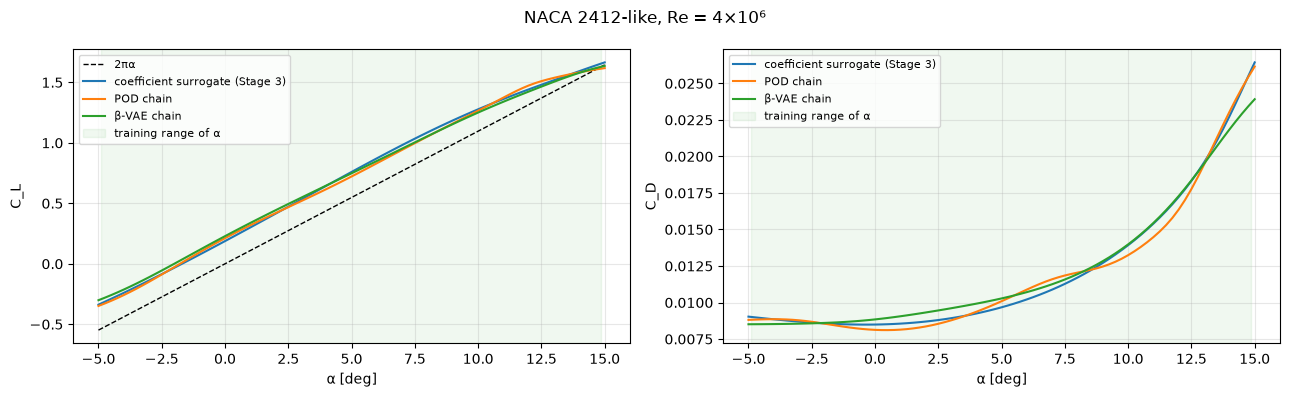

,law,target CL at 5 deg (zero gust),CD at 5 deg,lift slope 4-6 deg [1/rad],max |dCL| vs Stage 3 surrogate,at alpha [deg],max |dCD| vs Stage 3 surrogate,dCD at alpha [deg]
0,coefficient surrogate (Stage 3),0.75949,0.00967,6.50950,0.00000,-5.00,0.00000,-5.0
1,POD chain,0.72205,0.01009,6.13788,0.04743,15.00,0.00096,11.5
2,β-VAE chain,0.74833,0.01028,5.82069,0.04080,-0.25,0.00252,15.0
3,thin airfoil 2*pi*alpha,0.54831,NaN,6.28319,0.21468,6.50,NaN,NaN


In [12]:
# ================================================================
# A. LOAD THE STAGE 5 CHAIN (Keras) AND COMPARE THE LAWS
# ================================================================
class Sampling(layers.Layer):          # from Stage 5 (needed only to reload the encoder; not used here)
    def call(self, inputs):
        mu, logvar = inputs
        return mu + tf.exp(0.5 * logvar) * tf.random.normal(shape=tf.shape(mu))


chain_scalers = joblib.load(L12 / "chain_scalers.joblib")
parameter_scaler_12, coef_scaler_12 = chain_scalers["parameter_scaler"], chain_scalers["coef_scaler"]
print("Stage 5 parameter units:", chain_scalers["parameter_units"])
L12_CHAIN = {}
for kind, slug in (("POD", "pod"), ("beta-VAE", "vae")):
    info = json.load(open(L12 / f"latent_surrogate_{slug}_seed2026.json"))
    L12_CHAIN[kind] = {"surrogate": keras.models.load_model(L12 / f"latent_surrogate_{slug}_seed2026.keras"), "scale": info["scale"],
                       "head": keras.models.load_model(L12 / f"aerodynamic_head_{slug}_seed2026.keras"),
                       "z_scaler": joblib.load(L12 / f"aerodynamic_head_{slug}_seed2026_latent_scaler.joblib")}


def l12_params(reynolds, alpha_deg, m=2.0, p=4.0, t=12.0):
    """NACA digits and Re (Stage 3 convention) -> Stage 5 inputs after prepare_parameters and parameter_scaler."""
    a = np.atleast_1d(np.asarray(alpha_deg, dtype=np.float64))
    raw = np.column_stack([np.full_like(a, m / 100.0), np.full_like(a, p / 10.0), np.full_like(a, t / 100.0),
                           np.full_like(a, np.log10(reynolds)), a])
    return parameter_scaler_12.transform(raw)


def l12_keras(kind, reynolds, alpha_deg, m=2.0, p=4.0, t=12.0):
    c = L12_CHAIN[kind]
    z = c["surrogate"].predict(l12_params(reynolds, alpha_deg, m, p, t), verbose=0) * c["scale"]
    return coef_scaler_12.inverse_transform(c["head"].predict(c["z_scaler"].transform(z), verbose=0))


BASE = dict(reynolds=4.0e6, m=2.0, p=4.0, t=12.0)
alpha_A = np.round(np.linspace(-5.0, 15.0, 81), 4)
law = {"coefficient surrogate (Stage 3)": np.array([keras_predict_airfrans_aero(BASE["reynolds"], a, 2.0, 4.0, 12.0) for a in alpha_A]),
       "POD chain": l12_keras("POD", alpha_deg=alpha_A, **BASE),
       "β-VAE chain": l12_keras("beta-VAE", alpha_deg=alpha_A, **BASE)}
thin = 2.0 * np.pi * np.deg2rad(alpha_A)
partA = pd.DataFrame({"alpha_deg": alpha_A, "CL thin airfoil 2*pi*alpha": thin,
                      **{f"CL {k}": v[:, 0] for k, v in law.items()}, **{f"CD {k}": v[:, 1] for k, v in law.items()}})
partA.to_csv(RES / "A_polars_at_10_4_operating_point.csv", index=False)

rows = []
i5, i4, i6 = [int(np.argmin(np.abs(alpha_A - a))) for a in (5.0, 4.0, 6.0)]
ref = law["coefficient surrogate (Stage 3)"]
for name, v in list(law.items()) + [("thin airfoil 2*pi*alpha", np.column_stack([thin, np.full_like(thin, np.nan)]))]:
    slope = (v[i6, 0] - v[i4, 0]) / np.deg2rad(alpha_A[i6] - alpha_A[i4])
    dcl = v[:, 0] - ref[:, 0]; dcd = v[:, 1] - ref[:, 1]
    rows.append({"law": name, "target CL at 5 deg (zero gust)": v[i5, 0], "CD at 5 deg": v[i5, 1], "lift slope 4-6 deg [1/rad]": slope,
                 "max |dCL| vs Stage 3 surrogate": np.nanmax(np.abs(dcl)), "at alpha [deg]": alpha_A[int(np.nanargmax(np.abs(dcl)))],
                 "max |dCD| vs Stage 3 surrogate": np.nanmax(np.abs(dcd)) if np.isfinite(dcd).any() else np.nan,
                 "dCD at alpha [deg]": alpha_A[int(np.nanargmax(np.abs(dcd)))] if np.isfinite(dcd).any() else np.nan})
partA_summary = pd.DataFrame(rows); partA_summary.to_csv(RES / "A_summary.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(alpha_A, thin, "k--", lw=1, label="2πα")
for k, v in law.items():
    ax[0].plot(alpha_A, v[:, 0], label=k); ax[1].plot(alpha_A, v[:, 1], label=k)
for a, yl in zip(ax, ["C_L", "C_D"]):
    a.axvspan(TRUST_LO, TRUST_HI, color="tab:green", alpha=0.07, label="training range of α")
    a.set_xlabel("α [deg]"); a.set_ylabel(yl); a.grid(alpha=0.3); a.legend(fontsize=8)
fig.suptitle("NACA 2412-like, Re = 4×10⁶"); fig.tight_layout(); fig.savefig(RES / "A_polars.png", dpi=120); plt.show()
partA_summary.round(5)

## B. The Stage 4 environment with Stage 5's aerodynamic function

`Stage5ChainEnv` subclasses `AirfoilSurrogateGymEnv` and replaces `_aero`, so that $(C_{L,qs}, C_D)$ at the equivalent angle come from the Stage 5 β-VAE chain (latent surrogate + aerodynamic head), evaluated as a NumPy forward pass of the same weights. Dynamics, observation, action, reward and gust are inherited unchanged.

The parent class also calls the Stage 3 function in two other places: to set the zero-gust target lift (`cl_target=None`, constructor) and the initial lift (`reset`). Left alone, the new environment would aim at Stage 3's equilibrium lift and start from it. The subclass therefore sets both from the same Stage 5 function — the only other lines it changes.

In [13]:
# ================================================================
# B. NUMPY FORWARD PASS OF THE STAGE 5 CHAIN, CHECK AND TIMING
# ================================================================
def dense_stack(model):
    return [(l.get_weights()[0], l.get_weights()[1], l.activation.__name__) for l in model.layers]


def run_stack(stack, h):
    for w, b, act in stack:
        h = h @ w + b
        if act == "tanh":
            h = np.tanh(h)
        elif act != "linear":
            raise ValueError(act)
    return h


_c = L12_CHAIN["beta-VAE"]
_sur, _head = dense_stack(_c["surrogate"]), dense_stack(_c["head"])
_pm, _ps = parameter_scaler_12.mean_, parameter_scaler_12.scale_
_zm, _zs = _c["z_scaler"].mean_, _c["z_scaler"].scale_
_cm, _cs = coef_scaler_12.mean_, coef_scaler_12.scale_
_scale = _c["scale"]


def l12_fast(reynolds, alpha_deg, m=2.0, p=4.0, t=12.0):
    x = (np.array([m / 100.0, p / 10.0, t / 100.0, np.log10(reynolds), alpha_deg]) - _pm) / _ps
    z = run_stack(_sur, x) * _scale
    cl, cd = run_stack(_head, (z - _zm) / _zs) * _cs + _cm
    return float(cl), float(cd)


rng_b = np.random.default_rng(0)
lo_tr, hi_tr = cfd_train[["Re", "alpha_deg", "m", "p", "t"]].min().to_numpy(), cfd_train[["Re", "alpha_deg", "m", "p", "t"]].max().to_numpy()
probe = rng_b.uniform(lo_tr, hi_tr, size=(200, 5))
diff_b = max(np.abs(np.subtract(l12_keras("beta-VAE", q[0], q[1], q[2], q[3], q[4])[0], l12_fast(*q))).max() for q in probe[:50])
timing = []
for rep in range(3):
    t0 = time.perf_counter(); [l12_keras("beta-VAE", *q) for q in probe[:30]]; tk = (time.perf_counter() - t0) / 30
    t0 = time.perf_counter(); [l12_fast(*q) for q in probe]; tf_ = (time.perf_counter() - t0) / 200
    t0 = time.perf_counter(); [fast_predict_airfrans_aero(*q) for q in probe]; t3 = (time.perf_counter() - t0) / 200
    timing.append({"repeat": rep, "Stage 5 chain, Keras [ms]": 1e3 * tk, "Stage 5 chain, NumPy [ms]": 1e3 * tf_,
                   "Stage 3 surrogate, NumPy [ms]": 1e3 * t3})
timing = pd.DataFrame(timing); timing.to_csv(RES / "B_timing.csv", index=False)
print(f"max |Keras - NumPy| over 50 random inputs inside the training ranges: {diff_b:.2e}")
print("time per call (Apple M3 Max, 3 repeats):"); print(timing.round(4).to_string(index=False))


class Stage5ChainEnv(AirfoilSurrogateGymEnv):
    """Stage 4 environment with the steady aerodynamic function of Stage 5 (beta-VAE chain)."""

    def __init__(self, cl_target=None, **kw):
        super().__init__(cl_target=cl_target, **kw)
        if cl_target is None:                      # zero-gust target from the same function
            self.cl_target = l12_fast(self.reynolds, self.alpha0_deg, self.naca_m, self.naca_p, self.naca_t)[0]
        self.reset()

    def _aero(self, gust_angle_deg):               # the exchanged aerodynamic function
        alpha_eq_deg = self._equivalent_alpha_deg(gust_angle_deg)
        cl_qs, cd = l12_fast(self.reynolds, alpha_eq_deg, self.naca_m, self.naca_p, self.naca_t)
        return cl_qs, cd, alpha_eq_deg

    def reset(self, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        self.cl, self.cd = l12_fast(self.reynolds, self.alpha0_deg, self.naca_m, self.naca_p, self.naca_t)   # initial state from the same function
        return self._get_obs(), info


check_env(Stage5ChainEnv(), warn=True)
print(f"Zero-gust target CL: Stage 3 surrogate {AirfoilSurrogateGymEnv().cl_target:.4f}, Stage 5 chain {Stage5ChainEnv().cl_target:.4f}")

max |Keras - NumPy| over 50 random inputs inside the training ranges: 3.63e-07
time per call (Apple M3 Max, 3 repeats):
 repeat  Stage 5 chain, Keras [ms]  Stage 5 chain, NumPy [ms]  Stage 3 surrogate, NumPy [ms]
      0                    37.2040                     0.0140                         0.0112
      1                    40.4561                     0.0145                         0.0120
      2                    40.6542                     0.0141                         0.0111
Zero-gust target CL: Stage 3 surrogate 0.7595, Stage 5 chain 0.7483


## C. PPO in both environments, cross-tested in both

PPO with the settings of Stage 4 (learning rate 3e-4, 1,024 steps per update, batch 64, γ 0.99), 50,000 steps, random gusts, seeds 0, 1 and 2. The seed-0 agent in the Stage 3 environment is exactly Stage 4's Experiment 1 agent (same settings and seed); it is loaded from that run rather than trained again, and its score is checked against Experiment 1. Every agent is tested in both environments on the same five gusts (`SUITE`): the fixed gust of Stage 4 and its four unseen gusts.

In [14]:
# ================================================================
# C. TRAIN (OR LOAD) THE SIX AGENTS AND CROSS-TEST THEM
# ================================================================
ENVS = {"Stage 3 surrogate env": AirfoilSurrogateGymEnv, "Stage 5 chain env": Stage5ChainEnv}


def ppo_agent(env_name, seed):
    if env_name == "Stage 3 surrogate env" and seed == 0:
        path = R104 / "exercises" / "ex1_ppo.zip"
        print("loading Stage 4 Exercise 1 agent:", path); return PPO.load(path), "loaded from Stage 4 Exercise 1"
    tag = f"ppo_{'surrogate' if env_name.startswith('Stage 3') else 'l12chain'}_seed{seed}"
    path = MODELS / f"{tag}.zip"
    env = Monitor(ENVS[env_name](random_gust=True), filename=str(MODELS / f"{tag}_monitor.csv"))
    if path.exists():
        return PPO.load(path, env=env), "loaded"
    agent = PPO("MlpPolicy", env, learning_rate=3e-4, n_steps=1024, batch_size=64, gamma=0.99, verbose=0, seed=seed)
    t0 = time.time(); agent.learn(total_timesteps=TOTAL_TIMESTEPS); agent.save(path)
    return agent, f"trained in {time.time() - t0:.0f} s"


agents = {}
for env_name in ENVS:
    for s in PPO_SEEDS:
        agents[(env_name, s)], how = ppo_agent(env_name, s); print(f"{env_name}, seed {s}: {how}")

rows = []
for (train_env, s), agent in agents.items():
    for test_env, cls in ENVS.items():
        rows.append({"trained in": train_env, "seed": s, "tested in": test_env, **suite_metrics(agent, "PPO", env_cls=cls)})
for test_env, cls in ENVS.items():
    rows.append({"trained in": "uncontrolled", "seed": "-", "tested in": test_env, **suite_metrics(ZeroPolicy(), "uncontrolled", env_cls=cls)})
partC_runs = pd.DataFrame(rows).drop(columns="configuration")
partC_runs.to_csv(RES / "C_cross_test_runs.csv", index=False)
chk = partC_runs[(partC_runs["trained in"] == "Stage 3 surrogate env") & (partC_runs.seed == 0) & (partC_runs["tested in"] == "Stage 3 surrogate env")]
print("Check against Stage 4 Exercise 1 (PPO, mean RMSE 0.00979 there):", round(float(chk.mean_RMSE.iloc[0]), 5))

cols = ["mean_RMSE", "mean_abs_flap_deg", "max_abs_flap_deg", "alpha_eq_min", "alpha_eq_max", "fraction_outside_trusted"]
trained = partC_runs[partC_runs["trained in"] != "uncontrolled"]
g = trained.groupby(["trained in", "tested in"], sort=False)[cols]
partC = g.mean().add_suffix(" mean").join(g.std().add_suffix(" std")).reset_index()
partC = pd.concat([partC, partC_runs[partC_runs["trained in"] == "uncontrolled"][["trained in", "tested in"] + cols].add_suffix("")
                   .rename(columns={c: c + " mean" for c in cols})], ignore_index=True)
partC["alpha_eq range (min over runs, max over runs)"] = [
    f"{trained[(trained['trained in'] == r['trained in']) & (trained['tested in'] == r['tested in'])].alpha_eq_min.min():.2f} to "
    f"{trained[(trained['trained in'] == r['trained in']) & (trained['tested in'] == r['tested in'])].alpha_eq_max.max():.2f}"
    if r["trained in"] != "uncontrolled" else f"{r['alpha_eq_min mean']:.2f} to {r['alpha_eq_max mean']:.2f}" for _, r in partC.iterrows()]
partC.to_csv(RES / "C_cross_test_summary.csv", index=False)
print(f"Trusted range of the equivalent angle: {TRUST_LO:.2f} to {TRUST_HI:.2f} deg")
partC.round(5)

loading Stage 4 Exercise 1 agent: ../../airfoil-cfd-surrogate-drl/models/04_airfoil_gust_control_cfd_surrogate/exercises/ex1_ppo.zip


Stage 3 surrogate env, seed 0: loaded from Stage 4 Exercise 1
Stage 3 surrogate env, seed 1: loaded
Stage 3 surrogate env, seed 2: loaded
Stage 5 chain env, seed 0: loaded
Stage 5 chain env, seed 1: loaded
Stage 5 chain env, seed 2: loaded


Check against Stage 4 Exercise 1 (PPO, mean RMSE 0.00979 there): 0.00979
Trusted range of the equivalent angle: -4.91 to 14.84 deg


,trained in,tested in,mean_RMSE mean,mean_abs_flap_deg mean,max_abs_flap_deg mean,alpha_eq_min mean,alpha_eq_max mean,fraction_outside_trusted mean,mean_RMSE std,mean_abs_flap_deg std,max_abs_flap_deg std,alpha_eq_min std,alpha_eq_max std,fraction_outside_trusted std,"alpha_eq range (min over runs, max over runs)"
0,Stage 3 surrogate env,Stage 3 surrogate env,0.00952,1.07406,11.85860,4.60532,5.45613,0.0,0.00065,0.05292,0.23960,0.18335,0.04823,0.0,4.42 to 5.49
1,Stage 3 surrogate env,Stage 5 chain env,0.01063,1.11036,11.86611,4.60048,5.50847,0.0,0.00040,0.05578,0.25639,0.19825,0.05546,0.0,4.40 to 5.55
2,Stage 5 chain env,Stage 3 surrogate env,0.00957,1.05737,11.81996,4.55821,5.46480,0.0,0.00157,0.05616,0.22748,0.18787,0.04589,0.0,4.38 to 5.51
3,Stage 5 chain env,Stage 5 chain env,0.01041,1.09282,11.82370,4.54966,5.52011,0.0,0.00179,0.05925,0.24446,0.20364,0.05257,0.0,4.35 to 5.57
4,uncontrolled,Stage 3 surrogate env,0.14963,0.00000,0.00000,-1.65443,11.65443,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-1.65 to 11.65
5,uncontrolled,Stage 5 chain env,0.14010,0.00000,0.00000,-1.65443,11.65443,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-1.65 to 11.65


## D. Steady pressure fields along one controlled flight

The Stage 5 chain can return the whole field, not only two coefficients. For the seed-0 agent trained in the Stage 5 chain environment, flying the fixed gust ($W_0 = 2.5$ m/s, $T_g = 1.3$ s), the pressure field is decoded before the gust, at its peak and after recovery. **These are steady fields at the equivalent angle of attack of that instant; the flap is not in them** — the database has no flap, and the equivalent angle only stands in for its effect on the coefficients.

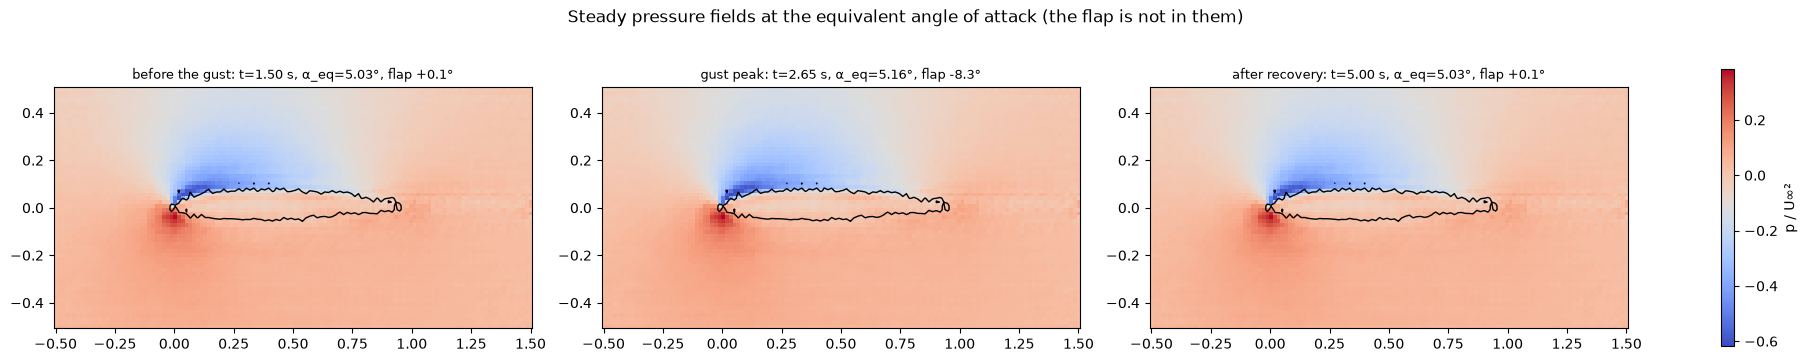

,moment,time_s,gust_angle_deg,flap_deg,alpha_eq_deg,CL,p_min,p_max
0,before the gust,1.50,0.0000,0.0621,5.0342,0.7518,-0.6064,0.3775
1,gust peak,2.65,4.7636,-8.2512,5.1566,0.7700,-0.6183,0.3833
2,after recovery,5.00,0.0000,0.0621,5.0342,0.7518,-0.6064,0.3775


In [15]:
# ================================================================
# D. DECODE PRESSURE FIELDS ALONG THE FLIGHT
# ================================================================
decoder_12 = keras.models.load_model(L12 / "beta_vae_decoder.keras")
stats = np.load(L12 / "channel_statistics.npz")
ch_names = list(stats["channel_names"].astype(str)); i_p, i_sdf = ch_names.index("p_over_Uinf2"), ch_names.index("sdf")
grid = np.load("../release_assets/airfrans_naca4_test.npz")
XG, YG = np.meshgrid(grid["x_grid"], grid["y_grid"], indexing="xy")

flight = fly(agents[("Stage 5 chain env", 0)], 2.5, 1.3, env_cls=Stage5ChainEnv)
k_peak = int(np.argmax(flight["gust_angle_deg"]))
moments = {"before the gust": int(np.argmin(np.abs(flight["time"] - 1.5))), "gust peak": k_peak,
           "after recovery": int(np.argmin(np.abs(flight["time"] - 5.0)))}
fields, rows = {}, []
for label, k in moments.items():
    a_eq = float(flight["alpha_eq_deg"][k])
    z = L12_CHAIN["beta-VAE"]["surrogate"].predict(l12_params(4.0e6, a_eq), verbose=0) * L12_CHAIN["beta-VAE"]["scale"]
    f = np.transpose(decoder_12.predict(z, verbose=0), (0, 3, 1, 2))[0] * stats["channel_std"][0] + stats["channel_mean"][0]
    fields[label] = f
    rows.append({"moment": label, "time_s": float(flight["time"][k]), "gust_angle_deg": float(flight["gust_angle_deg"][k]),
                 "flap_deg": float(flight["flap_deg"][k]), "alpha_eq_deg": a_eq, "CL": float(flight["cl"][k]),
                 "p_min": float(f[i_p].min()), "p_max": float(f[i_p].max())})
partD = pd.DataFrame(rows); partD.to_csv(RES / "D_flight_moments.csv", index=False)
vmin = min(f[i_p].min() for f in fields.values()); vmax = max(f[i_p].max() for f in fields.values())
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8), constrained_layout=True)
for ax, (label, f), r in zip(axes, fields.items(), rows):
    im = ax.pcolormesh(XG, YG, f[i_p], shading="auto", cmap="coolwarm", vmin=vmin, vmax=vmax)
    ax.contour(XG, YG, f[i_sdf], levels=[0.0], colors="black", linewidths=1.0)
    ax.set_aspect("equal"); ax.set_title(f"{label}: t={r['time_s']:.2f} s, α_eq={r['alpha_eq_deg']:.2f}°, flap {r['flap_deg']:+.1f}°", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label="p / U∞²")
fig.suptitle("Steady pressure fields at the equivalent angle of attack (the flap is not in them)")
fig.savefig(RES / "D_pressure_fields.png", dpi=110); plt.show()
partD.round(4)

## E. One training range for both models; how far they disagree outside it

Both aerodynamic functions were fitted on the same 378 training simulations (Stage 3 on the coefficient table, Stage 5 on the field files, whose case names and split agree one to one). Their input ranges are therefore the same box. A probe at $\alpha = 18^\circ$, outside the training range of the angle (−4.91° to 14.84°), shows how far the two extrapolate apart; a sweep from −10° to 20° shows where the disagreement starts.

Same 378 training simulations in both: True


Largest CL spread between the three: inside the range 0.0502; outside 0.1946 (at α = -10.00°)


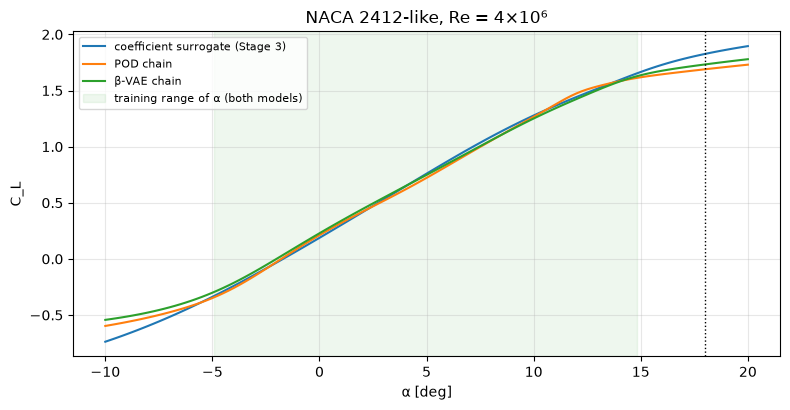

,parameter,Stage 3 training min,Stage 3 training max,Stage 5 training min,Stage 5 training max
0,m (NACA digit),6.000000e-03,6.998000e+00,0.006,6.998
1,p (NACA digit),0.000000e+00,6.992000e+00,0.000,6.992
2,t (NACA digit),5.094000e+00,1.994400e+01,5.094,19.944
3,Re,2.005321e+06,5.993590e+06,2005320.500,5993589.500
4,alpha [deg],-4.910000e+00,1.483700e+01,-4.910,14.837


,law,CL at 18 deg,CD at 18 deg,CL at 14.84 deg (edge)
0,coefficient surrogate (Stage 3),1.8259,0.0340,1.6539
1,POD chain,1.6892,0.0319,1.6128
2,β-VAE chain,1.7323,0.0279,1.6282


In [16]:
# ================================================================
# E. SHARED TRAINING RANGES AND AN OUTSIDE PROBE
# ================================================================
npz_train = np.load("../release_assets/airfrans_naca4_train.npz")
P12 = npz_train["parameters"].astype(np.float64)
same_names = sorted(npz_train["names"].astype(str)) == sorted(cfd_train["name"])
ranges = pd.DataFrame({
    "parameter": ["m (NACA digit)", "p (NACA digit)", "t (NACA digit)", "Re", "alpha [deg]"],
    "Stage 3 training min": [cfd_train.m.min(), cfd_train.p.min(), cfd_train.t.min(), cfd_train.Re.min(), cfd_train.alpha_deg.min()],
    "Stage 3 training max": [cfd_train.m.max(), cfd_train.p.max(), cfd_train.t.max(), cfd_train.Re.max(), cfd_train.alpha_deg.max()],
    "Stage 5 training min": [P12[:, 0].min() * 100, P12[:, 1].min() * 10, P12[:, 2].min() * 100, P12[:, 3].min(), P12[:, 4].min()],
    "Stage 5 training max": [P12[:, 0].max() * 100, P12[:, 1].max() * 10, P12[:, 2].max() * 100, P12[:, 3].max(), P12[:, 4].max()]})
ranges.to_csv(RES / "E_training_ranges.csv", index=False)
print("Same 378 training simulations in both:", same_names)

alpha_E = np.round(np.linspace(-10.0, 20.0, 121), 4)
lawE = {"coefficient surrogate (Stage 3)": np.array([keras_predict_airfrans_aero(4.0e6, a, 2.0, 4.0, 12.0) for a in alpha_E]),
        "POD chain": l12_keras("POD", alpha_deg=alpha_E, **BASE),
        "β-VAE chain": l12_keras("beta-VAE", alpha_deg=alpha_E, **BASE)}
probe18 = pd.DataFrame([{"law": k, "CL at 18 deg": float(v[np.argmin(np.abs(alpha_E - 18.0)), 0]),
                         "CD at 18 deg": float(v[np.argmin(np.abs(alpha_E - 18.0)), 1]),
                         "CL at 14.84 deg (edge)": float(np.interp(TRUST_HI, alpha_E, v[:, 0]))} for k, v in lawE.items()])
spread = np.ptp(np.stack([v[:, 0] for v in lawE.values()]), axis=0)
inside = (alpha_E >= TRUST_LO) & (alpha_E <= TRUST_HI)
print(f"Largest CL spread between the three: inside the range {spread[inside].max():.4f}; outside {spread[~inside].max():.4f} "
      f"(at α = {alpha_E[~inside][np.argmax(spread[~inside])]:.2f}°)")
pd.DataFrame({"alpha_deg": alpha_E, **{f"CL {k}": v[:, 0] for k, v in lawE.items()}, **{f"CD {k}": v[:, 1] for k, v in lawE.items()},
              "CL spread": spread}).to_csv(RES / "E_sweep_outside.csv", index=False)
probe18.to_csv(RES / "E_probe_18deg.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, v in lawE.items(): ax.plot(alpha_E, v[:, 0], label=k)
ax.axvspan(TRUST_LO, TRUST_HI, color="tab:green", alpha=0.08, label="training range of α (both models)")
ax.axvline(18.0, color="k", ls=":", lw=1); ax.set_xlabel("α [deg]"); ax.set_ylabel("C_L"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("NACA 2412-like, Re = 4×10⁶"); fig.tight_layout(); fig.savefig(RES / "E_outside_range.png", dpi=120); plt.show()
display(ranges)
probe18.round(4)

In [17]:
for p in sorted(RES.iterdir()): print(p)
for p in sorted(MODELS.iterdir()): print(p)

../results/06_field_model_in_control_loop/A_polars.png
../results/06_field_model_in_control_loop/A_polars_at_10_4_operating_point.csv
../results/06_field_model_in_control_loop/A_summary.csv
../results/06_field_model_in_control_loop/B_timing.csv
../results/06_field_model_in_control_loop/C_cross_test_runs.csv
../results/06_field_model_in_control_loop/C_cross_test_summary.csv
../results/06_field_model_in_control_loop/D_flight_moments.csv
../results/06_field_model_in_control_loop/D_pressure_fields.png
../results/06_field_model_in_control_loop/E_outside_range.png
../results/06_field_model_in_control_loop/E_probe_18deg.csv
../results/06_field_model_in_control_loop/E_sweep_outside.csv
../results/06_field_model_in_control_loop/E_training_ranges.csv
../models/06_field_model_in_control_loop/ppo_l12chain_seed0.zip
../models/06_field_model_in_control_loop/ppo_l12chain_seed0_monitor.csv
../models/06_field_model_in_control_loop/ppo_l12chain_seed1.zip
../models/06_field_model_in_control_loop/ppo_l12c